### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 7
### Due: Wednesday, Nov. 18 at 11.59pm CT
---

## Problem 1

This is a regression problem. Many of the parts require minor variations of code to switch to new techniques, but otherwise using a similar workflow. 

Note of warning: the data I have provided have associated uncertainties, `yerr`. `sklearn` and `astroML` have different formats for using uncertainties; in `sklearn` fitting you can provide `sample_weight=1/yerr**2`, while in `astroML` fitting you can directly provide `y_error=yerr`.

1. Read in `hw7_data_1.npy`. The dataset should consist of $500$ samples. The first two columns are the two data features, `X`. The third column is the target labels, `y`, and the final column are the heteroscedastic uncertainties on the labels, `yerr`. Make a 2-panel scatter plot of the labels versus each feature.


2. Use multivariate linear regression on this data with its uncertainties (`astroML` rather than plain `sklearn` is the better option here). Print the best-fit intercept and slopes for the features. Make a prediction `Xgrid` over $50$ values from the min to the max value of each feature, and plot the best-fit model on a duplicate of the $2$-panel plot from (1); does this look like a good description of the data?


3. Make a new two-dimensional prediction meshgrid `Xgrid` over the $2$-D feature space, use your best-fit model to predict the labels, and make a $3$-D interactive plot showing the data and your best-fit over the entire space. You may find the following code useful.

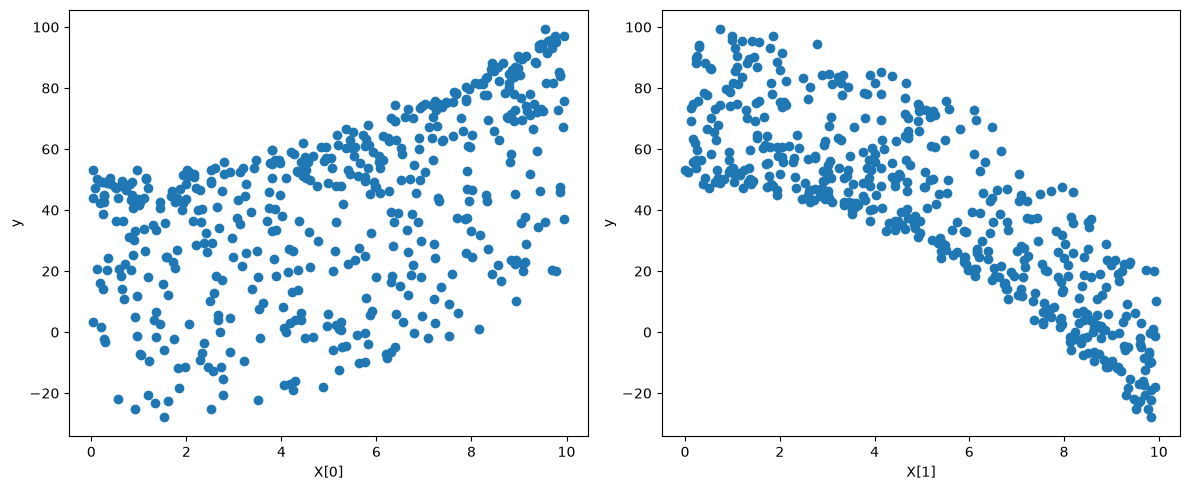

In [13]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load('hw_data/hw7_data_1.npy')

X = data[:, :2]
y = data[:, 2]
yerr = data[:, 3]

plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y)
plt.xlabel('X[0]')
plt.ylabel('y')

plt.subplot(1, 2, 2)
plt.scatter(X[:, 1], y)
plt.xlabel('X[1]')
plt.ylabel('y')

plt.tight_layout()
plt.show()

Best Fit Coeffs: [57.10102323  4.94873016 -8.30023407]


C:\Users\itsya\anaconda3\envs\astr3300_3\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


Text(0, 0.5, 'y')

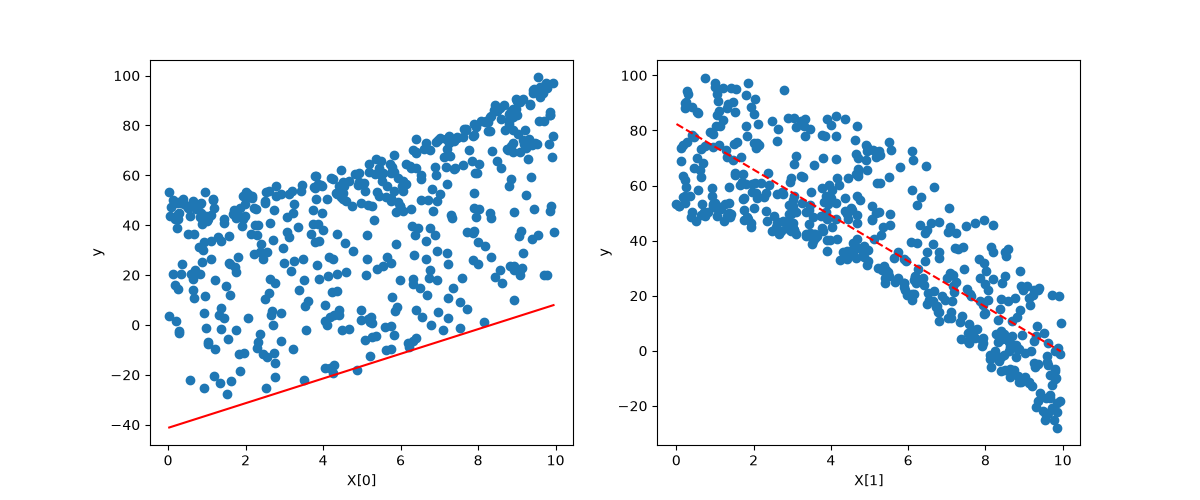

In [9]:
from astroML.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y, yerr)

print("Best Fit Coeffs:", model.coef_)

Xgrid = np.linspace(X.min(axis=0), X.max(axis=0), 50)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], y)
plt.plot(Xgrid[:, 0], + model.coef_[1]*Xgrid[:, 0] + model.coef_[2]*X[:, 1].mean(), '-r')
plt.xlabel ('X[0]')
plt.ylabel('y')

plt.subplot(1, 2, 2)
plt.scatter(X[:, 1], y)
plt.plot(Xgrid[:, 1], model.coef_[0] + model.coef_[1]*X[:, 0].mean() + model.coef_[2]*Xgrid[:, 1], 'r--')
plt.xlabel('X[1]')
plt.ylabel('y')

#Base code taken from lecture 17

The linear model shows the general trends but comparison to the scatter plots show that it doesn't necessarily describe the data accurately.

In [10]:
#Create Meshgrid
Xgrid = np.linspace(X.min(axis=0), X.max(axis=0),50)
X0, X1 = np.meshgrid(Xgrid[:, 0], Xgrid[:, 1])
Xgrid = np.column_stack((X0.flatten(), X1.flatten()))
y_pred = model.predict(Xgrid)

In [4]:
# install the relevant interactive plot packages
# only do this once
!pip install ipywidgets ipympl

<function matplotlib.pyplot.show(block=None)>

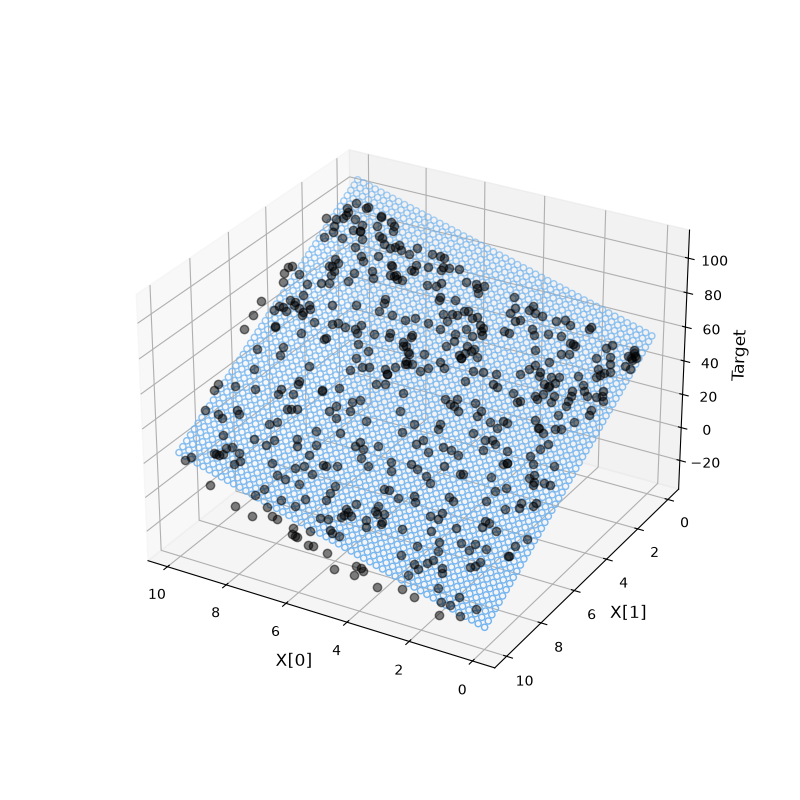

In [13]:
# Makes the plot interactive. 
# You can pan the image.

### always do this line at the start 
### of an interactive plotting cell
%matplotlib widget 
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k', 
        zorder=15, linestyle='none', 
        marker='o', alpha=0.5)
ax.scatter(X0.flatten(), X1.flatten(), y_pred, 
           facecolor=(0,0,0,0), s=20, 
           edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)
plt.show

In [14]:
### Always do this line at the start
### of a static plotting cell
%matplotlib inline

4. Sticking with a linear model, now attempt a `GridSearchCV` procedure on the data to find the best `Ridge` regression hyper-parameters. Use the following `param_grid`:
```
ridge_params = {'alpha': [0.05,0.1,0.2,0.5,1.0], 'solver': ['svd', 'lsqr']}
```
What are the `best_params_` and the `best_score_` from this? Fit the data with the best options, and visualize interactively. Try `RidgeCV` also; what cross-validated `alpha_` does it return, and does this agree with `GridSeachCV`? *(Hint: remember to revert to inline matplotlib when you're done each time you make an interactive plot.)*


5. Now model the data using Gaussian process regression and the default kernel. Check what the fit looks like with and with and without uncertainties accounted for. *(Hint: GPR in `sklearn` takes an `alpha` parameter equal to `(yerr/y)**2`.)*


6. Let's look finally at polynomial fitting. Fit a $4$th degree polynomial to the data. Print the best-fit regression coefficients, predict on the 2D meshgrid, and visualize interactively as before. How does this look compared to the linear model and GPR models?


7. Sticking with polynomial fitting, let's find the optimal hyper-parameters through cross-validation. 
- Using `sklearn.model_selection.train_test_split`, first do a train-test split with a `test_size` of $20\%$. Then split out $20\%$ of the training set itself as a cross-validation set (leaving a somewhat smaller set to use for training). Note that you'll need to simultaneously split out `yerr` as well by just providing this as another array to `train_test_split`.
- Compute the training and cross-validation rms errors (and from those, the BIC values) as a function of polynomial degree from $1$ to $10$ inclusive. Plot the rms errors and BIC values as a function of the polynomial degree. 
- Choose the optimal polynomial degree, and train on all training data from the first `train_test_split` operation. Predict the labels of the held-out test set, and finally compute the testing rms error.

In [16]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_params = {'alpha': [0.05, 0.1, 0.2, 0.5, 1.0], 'solver': ['svd', 'lsqr']}

grid = GridSearchCV(Ridge(), ridge_params)
grid.fit(X, y)

print("Best parameters:", grid.best_params_)
print("Best score:", grid.best_score_)

Best parameters: {'alpha': 1.0, 'solver': 'svd'}
Best score: 0.9290800590702192


In [17]:
ridge_model = Ridge(alpha=1.0, solver='svd')
ridge_model.fit(X, y)

ridge_pred = ridge_model.predict(Xgrid)

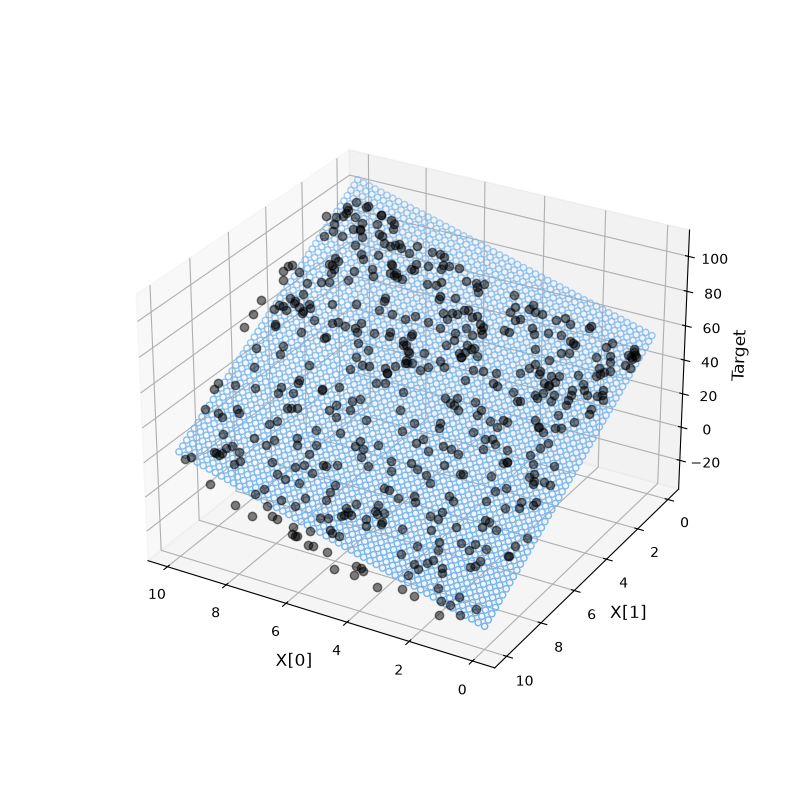

In [19]:
%matplotlib widget

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(X0.flatten(), X1.flatten(), ridge_pred, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')

ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

plt.show()

In [21]:
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(alphas=[0.05, 0.1, 0.2, 0.5, 1.0])
ridge_cv.fit(X, y)

print("RidgeCV alpha:", ridge_cv.alpha_)
print("GridSearchCV alpha:", grid.best_params_['alpha'])

RidgeCV alpha: 1.0
GridSearchCV alpha: 1.0


GridSearchCV found alpha=1.0 and solver='svd' to be the best parameters and a cross validation score of 0.9291. The regression surface follows the overall data trend and looks close to the linear regression model. RidgeCV agreed with alpha=0.1 so they both found the same answer for the best regularization parameter.

In [22]:
from sklearn.gaussian_process import GaussianProcessRegressor

gp = GaussianProcessRegressor()
gp.fit(X, y)

gp_pred = gp.predict(Xgrid)

C:\Users\itsya\anaconda3\envs\astr3300_3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


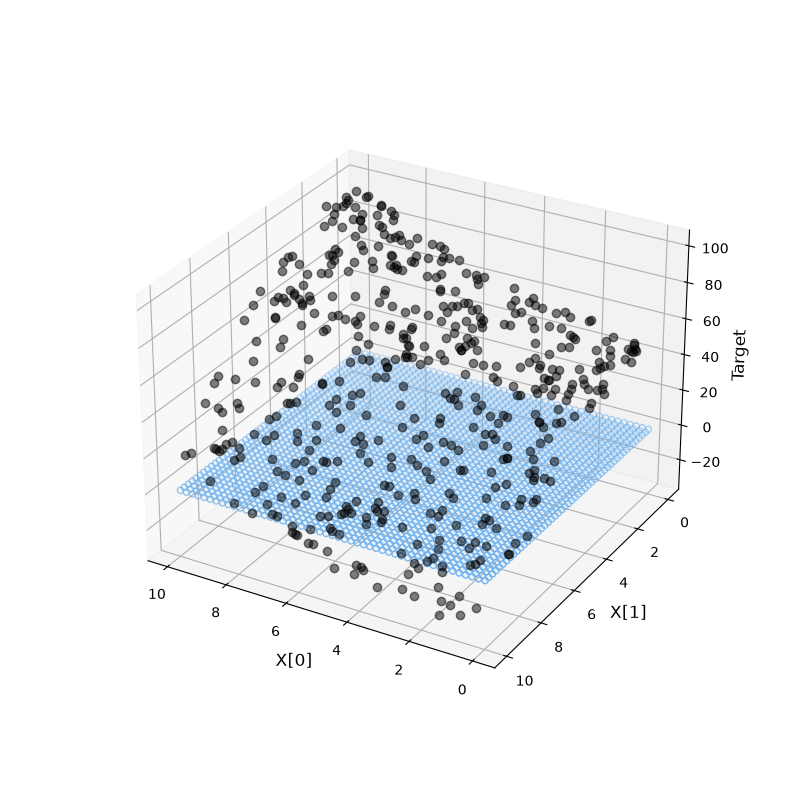

In [24]:
%matplotlib widget

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(X0.flatten(), X1.flatten(), gp_pred, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')

ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

plt.show()

In [25]:
%matplotlib inline

In [26]:
gp_err = GaussianProcessRegressor(alpha=(yerr/y)**2)
gp_err.fit(X, y)

gp_err_pred = gp_err.predict(Xgrid)

C:\Users\itsya\anaconda3\envs\astr3300_3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


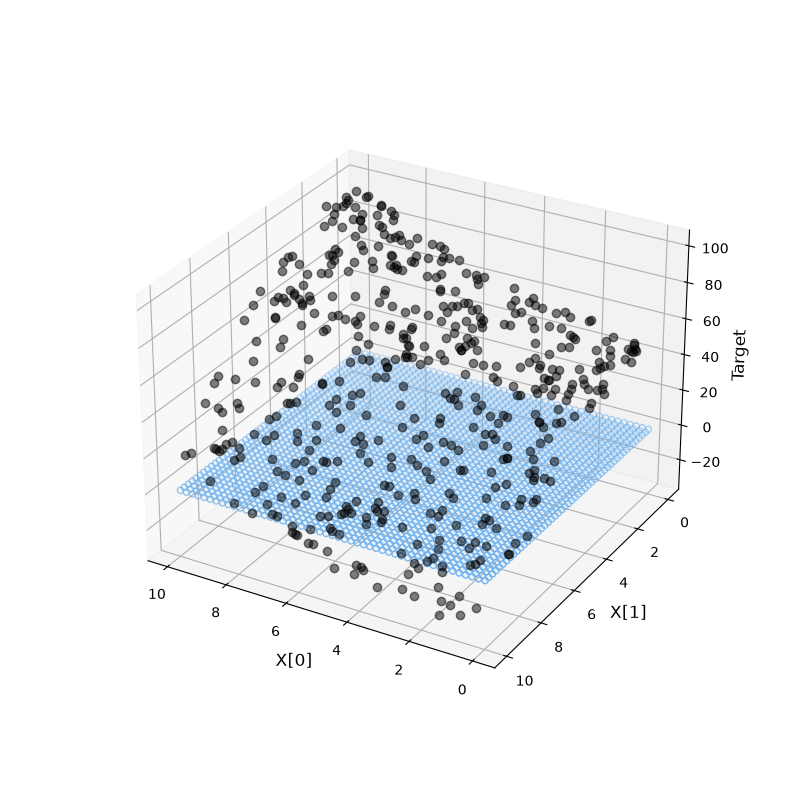

In [27]:
%matplotlib widget

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(X0.flatten(), X1.flatten(), gp_err_pred, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')

ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

plt.show()

In [28]:
%matplotlib inline

In [29]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=4)
X_poly = poly.fit_transform(X)

poly_model = LinearRegression()
poly_model.fit(X_poly, y, sample_weight=1/yerr**2)

print("Best Fit Coeffs:", poly_model.coef_)

Xgrid_poly = poly.transform(Xgrid)
poly_pred = poly_model.predict(Xgrid_poly)

Best Fit Coeffs: [ 1.84050777e-28  5.54313398e-01 -2.07866484e-01  2.86536907e-01
  2.93842380e-03 -7.82230112e-01  2.47603263e-02  2.45748271e-02
 -2.22233559e-02  9.68417971e-03 -9.95958746e-04 -1.12284370e-03
 -1.14462222e-03  2.10142159e-03 -1.08539159e-03]


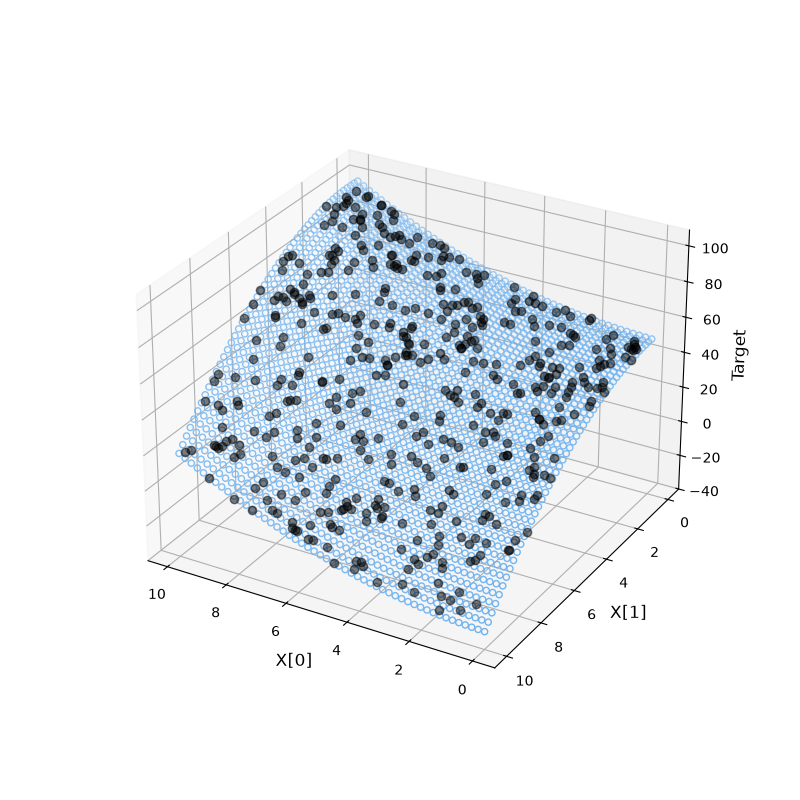

In [30]:
%matplotlib widget

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k', zorder=15, linestyle='none', marker='o', alpha=0.5)
ax.scatter(X0.flatten(), X1.flatten(), poly_pred, facecolor=(0,0,0,0), s=20, edgecolor='#70b3f0')

ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

plt.show()

the 4th degree regression results in a curved surface roughly following the distribution of the data. It appeared to produce a more direct relationship with the features and target than linear regression or ridge.

In [31]:
%matplotlib inline

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, yerr_train, yerr_test = train_test_split(X, y, yerr, test_size=0.2, random_state=0)

X_train2, X_cv, y_train2, y_cv, yerr_train2, yerr_cv = train_test_split(X_train, y_train, yerr_train, test_size=0.2, random_state=0)

In [37]:
degrees = np.arange(1, 11)

rms_train = []
rms_cv = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train2)
    X_cv_poly = poly.transform(X_cv)

    model = LinearRegression()
    model.fit(X_train_poly, y_train2, sample_weight=1/yerr_train2**2)

    y_train_pred = model.predict(X_train_poly)
    y_cv_pred = model.predict(X_cv_poly)

    rms_train.append(np.sqrt(np.mean((y_train2 - y_train_pred)**2)))
    rms_cv.append(np.sqrt(np.mean((y_cv - y_cv_pred)**2)))

print("Training RMS:", rms_train)
print("Cross Validation RMS:", rms_cv)

Training RMS: [np.float64(7.713389742529704), np.float64(1.9597076815216683), np.float64(1.9393268947596511), np.float64(1.931094854658589), np.float64(1.9289909959493454), np.float64(1.9018510245523403), np.float64(1.958979993850837), np.float64(2.3059806851838682), np.float64(3.6753224319326967), np.float64(4.448695391994446)]
Cross Validation RMS: [np.float64(8.073331817056284), np.float64(1.9845467329900222), np.float64(1.9772225893223845), np.float64(1.9640979822776135), np.float64(1.9916850391686174), np.float64(2.017387348630415), np.float64(2.052480208285554), np.float64(2.5013020738597134), np.float64(4.245098505125753), np.float64(5.1750136731941065)]


In [38]:
bic_train = []
bic_cv = []

for i, degree in enumerate(degrees):
    k = (degree + 1)*(degree +2)//2

    n_train = len(y_train2)
    n_cv = len(y_cv)

    bic_train.append(n_train*np.log(rms_train[i]**2) + k*np.log(n_cv))
    bic_cv.append(n_cv*np.log(rms_cv[i]**2) + k*np.log(n_cv))

print("Training BIC:", bic_train)
print("Cross Validation BIC:", bic_cv)

Training BIC: [np.float64(1320.6390375211593), np.float64(456.8811646329126), np.float64(467.71847524663275), np.float64(486.9061590590474), np.float64(512.5006816852493), np.float64(534.1064324097945), np.float64(588.1042717960181), np.float64(731.915067946442), np.float64(1074.0616187608216), np.float64(1244.4847229169545)]
Cross Validation BIC: [np.float64(347.31668176703073), np.float64(135.9546465221983), np.float64(152.89116671322105), np.float64(173.7356951731066), np.float64(202.25952473520582), np.float64(234.9852709697388), np.float64(272.8007859782656), np.float64(343.88102669367015), np.float64(472.3338688223754), np.float64(552.2284748982449)]


In [39]:
%matplotlib inline

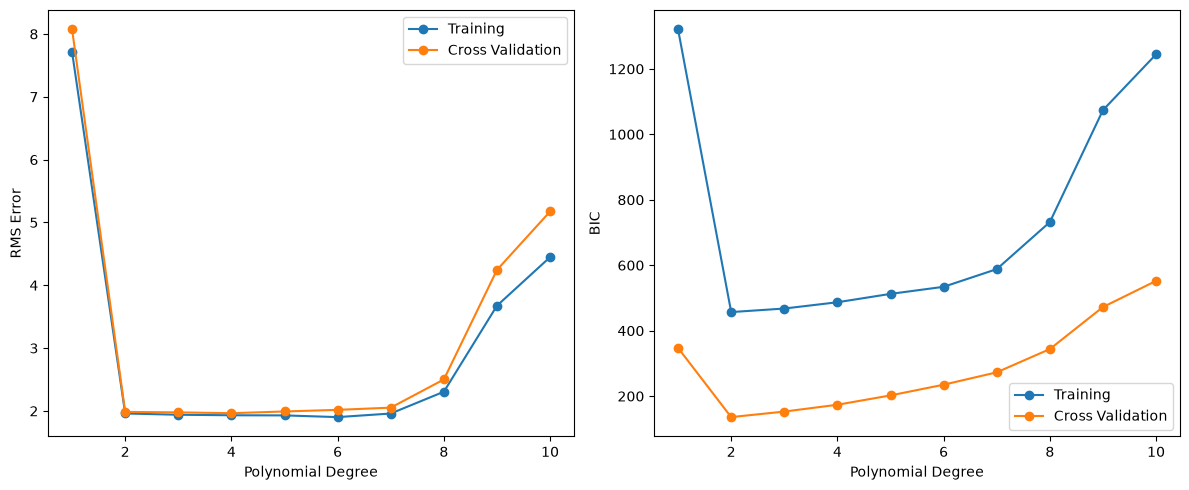

In [42]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(degrees, rms_train, 'o-', label='Training')
plt.plot(degrees, rms_cv, 'o-', label='Cross Validation')
plt.xlabel('Polynomial Degree')
plt.ylabel('RMS Error')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(degrees, bic_train, 'o-', label='Training')
plt.plot(degrees, bic_cv, 'o-', label='Cross Validation')
plt.xlabel('Polynomial Degree')
plt.ylabel('BIC')
plt.legend()

plt.tight_layout()
plt.show()

In [43]:
best_degree = 2

poly = PolynomialFeatures(degree=best_degree)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

final_model = LinearRegression()
final_model.fit(X_train_poly, y_train, sample_weight=1/yerr_train**2)

y_test_pred = final_model.predict(X_test_poly)
rms_test = np.sqrt(np.mean((y_test - y_test_pred)**2))

print("Optimal polynomial degree:", best_degree)
print("Testing RMS:", rms_test)

Optimal polynomial degree: 2
Testing RMS: 1.788774686814781


## Problem 2


1. Use the following code snippet to read in SDSS galaxy color data.
<!--```
from astroML.datasets import fetch_sdss_galaxy_colors
data = fetch_sdss_galaxy_colors()
```-->

`data = np.load('../hw_data/hw7_data_2.npy')`

This is a structured numpy array. Find and print all of the column names. Using the data, create arrays of $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create arrays of redshift and the spectral class. How many regular galaxies and how many quasars are in this sample?


2. Make a scatter plot of $(u-g)$ versus $(g-r)$, color coding by galaxy or quasar class. The plot should include appropriate axis labels and a legend. Set `xlim` between -0.5 and 2.5, and `ylim` between -0.5 and 1.5.


3. Stack all colors and the redshift into a data matrix, $X$. Create a target label array that has $0$ for a regular galaxy and $1$ for a quasar. Perform a train-test split, taking $20\%$ of the data for testing.


4. Create a compact `for` loop that iterates over the fitting of a Gaussian Naive Bayes classification algorithm to successively more features of the data. Within the loop, compute and plot an ROC curve. The end result should be a plot showing ROC curves for GNB classification with more and more features of the data, with appropriate axis labels and a legend. Use `xlim` between 0 and 0.01. Which feature seems to make the classification trivially easy? *Note: `predict_proba` returns an array with as many columns as classes. You've labeled quasars as $1$, so for the ROC curve you must make sure to access the relevant quasar probability-- you can find this by accessing the **classes_** attribute of the estimator.*


5. Repeat (4) for Quadratic Discriminant Analysis. 


6. Let's try classification with GMM Bayes. Restrict the training and testing to be just on the $4$ colors. Iterate now over number of components in the GMM Bayes fit up to $10$, plotting ROC curves for all, and find the number of components that gives the best performance.


7. Repeat (6) for $K$-nearest neighbor classification, looping over number of neighbors between 5 and 100 in steps of 10. Find the number that gives the best performance. 


8. Repeat (6) for Decision Tree classification, looping over the maximum tree depth between 1 and 10. Find the number that gives the best performance. 


9. Finally, plot the ROC curves for GNB, QDA, and the best-performing GMMBayes, KNN, and DT classification algorithms, all using just the 4 colors. What is the overall best-performing classifier? 


10. Make a 2-panel plot, showing in the left panel the color-coded training data in $(u-g)$ versus $(g-r)$ (similar to item 2 above), and in the right panel the same features of the testing data color coded by their predicted class from the tuned best-performing classifier. 

In [7]:
#Part 1
#load data
data = np.load('hw_data/hw7_data_2.npy')
print(data.dtype.names)

('u', 'g', 'r', 'i', 'z', 'specClass', 'redshift', 'redshift_err')


In [8]:
#create color indicies
ug = data['u'] - data['g']
gr = data['g'] - data['r']
ri = data['r'] - data['i']
iz = data['i'] - data['z']

redshift = data['redshift']
specClass = data['specClass']

print("Spectral Classes:", np.unique(specClass))

Spectral Classes: ['GALAXY' 'QSO']


In [9]:
#count observations using np.sum
n_galaxies = np.sum(specClass =='GALAXY')
n_quasars = np.sum(specClass == 'QSO')

print("Regular galaxies:", n_galaxies)
print("Quasars:", n_quasars)

Regular galaxies: 42808
Quasars: 7192


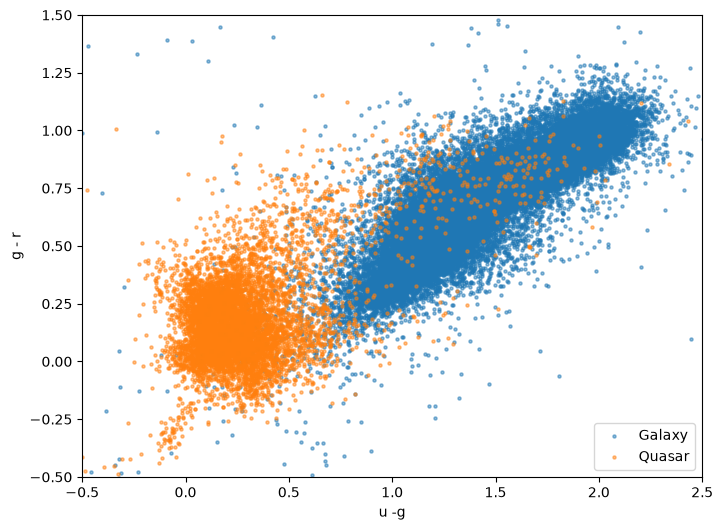

In [10]:
#Part 2
#make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(ug[specClass == 'GALAXY'], gr[specClass == 'GALAXY'], s=5, alpha=0.5, label='Galaxy')
plt.scatter(ug[specClass == 'QSO'], gr[specClass == 'QSO'], s=5, alpha=0.5, label='Quasar')

plt.xlabel('u -g')
plt.ylabel('g - r')
plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 1.5)
plt.legend()
plt.show()

In [16]:
#Part 3
#create training set
X = np.column_stack((ug, gr, ri, iz, redshift))
y = np.zeros(len(specClass))
y[specClass == 'QSO'] = 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (40000, 5)
Testing set: (10000, 5)


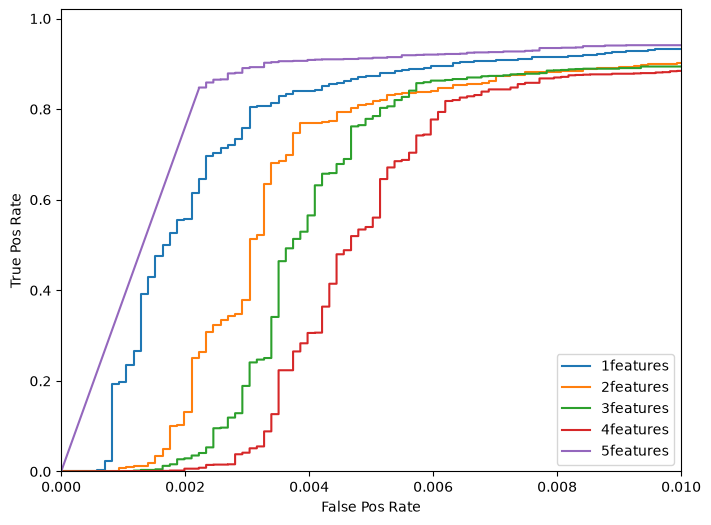

In [19]:
#Part4
#make ROC curves
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for i in range(1, 6):
    gnb = GaussianNB()
    gnb.fit(X_train[:, :i], y_train)

    qso_index = np.where(gnb.classes_ == 1)[0][0]
    y_prob = gnb.predict_proba(X_test[:, :i])[:, qso_index]

    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=str(i) + 'features')

plt.xlim(0, 0.01)
plt.ylim(0, 1.02)
plt.xlabel('False Pos Rate')
plt.ylabel('True Pos Rate')
plt.legend()
plt.show()
#base code taken from lecture 17

when added, thhe ROC curve shows improvement in the true positive rate with low false positive rates compared to just the 4 color features so redshift seems to make the classification easier

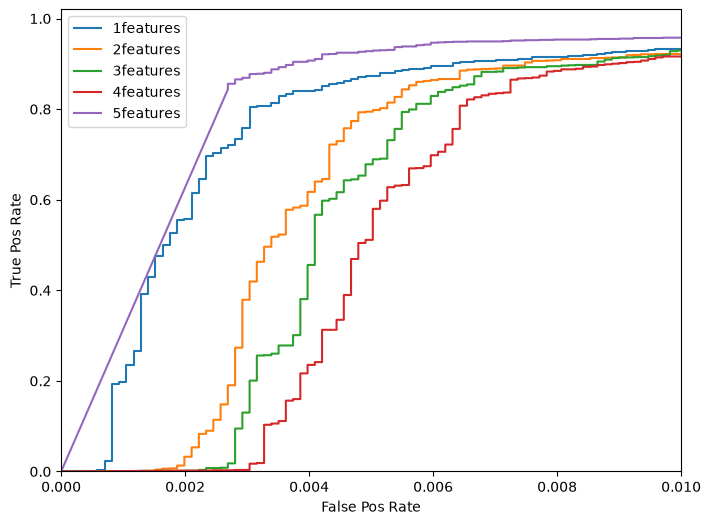

In [22]:
#Part5
#Reused code from 4
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis #changed

plt.figure(figsize=(8, 6))

for i in range(1, 6):
    qda = QuadraticDiscriminantAnalysis()
    qda.fit(X_train[:, :i], y_train)

    qso_index = np.where(gnb.classes_ == 1)[0][0]
    y_prob = qda.predict_proba(X_test[:, :i])[:, qso_index]

    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=str(i) + 'features')

plt.xlim(0, 0.01)
plt.ylim(0, 1.02)
plt.xlabel('False Pos Rate')
plt.ylabel('True Pos Rate')
plt.legend()
plt.show()

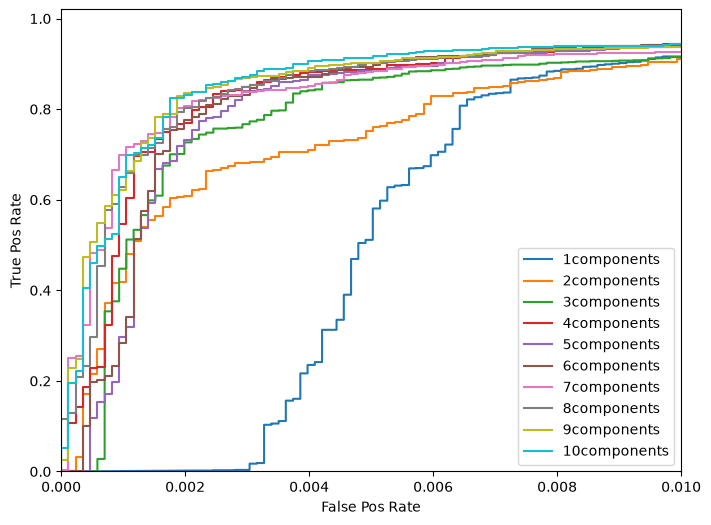

In [27]:
#Part6
#Reused code from 4
from astroML.classification import GMMBayes

plt.figure(figsize=(8, 6))

for i in range(1, 11):
    gmmb = GMMBayes(n_components=i, covariance_type='full')
    gmmb.fit(X_train[:, :4], y_train)

    qso_index = np.where(gmmb.classes_ == 1)[0][0]
    y_prob = gmmb.predict_proba(X_test[:, :4])[:, qso_index]

    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=str(i) + 'components')

plt.xlim(0, 0.01)
plt.ylim(0, 1.02)
plt.xlabel('False Pos Rate')
plt.ylabel('True Pos Rate')
plt.legend()
plt.show()

The GMM Bayes with 10 Gaussian components gives the highest true positive rate for most of the range so I'd say that is the best performance

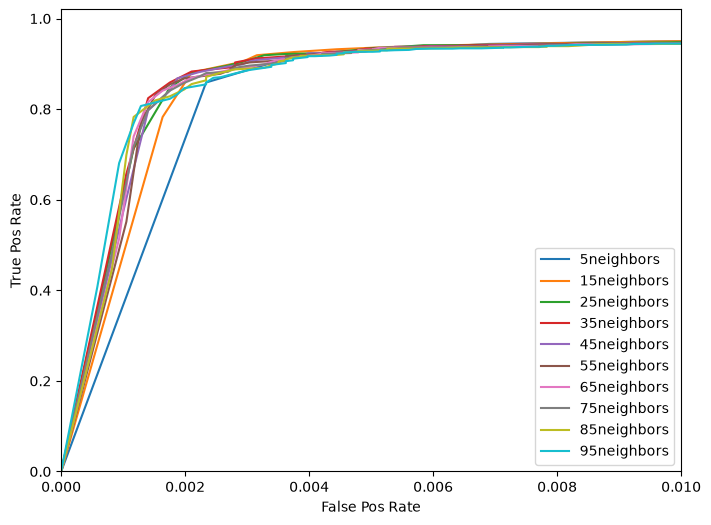

In [28]:
#Part7
#Reused code from 4
from sklearn.neighbors import KNeighborsClassifier

plt.figure(figsize=(8, 6))

for i in range(5, 101, 10):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train[:, :4], y_train)

    qso_index = np.where(knn.classes_ == 1)[0][0]
    y_prob = knn.predict_proba(X_test[:, :4])[:, qso_index]

    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=str(i) + 'neighbors')

plt.xlim(0, 0.01)
plt.ylim(0, 1.02)
plt.xlabel('False Pos Rate')
plt.ylabel('True Pos Rate')
plt.legend()
plt.show()

it looks like the classifier with 95 neighbors has the best proformance at lower false positive rates but between 0.001 and 0.003dips below the rest of the group and beyond that point seems to produce just about the same results as the rest 

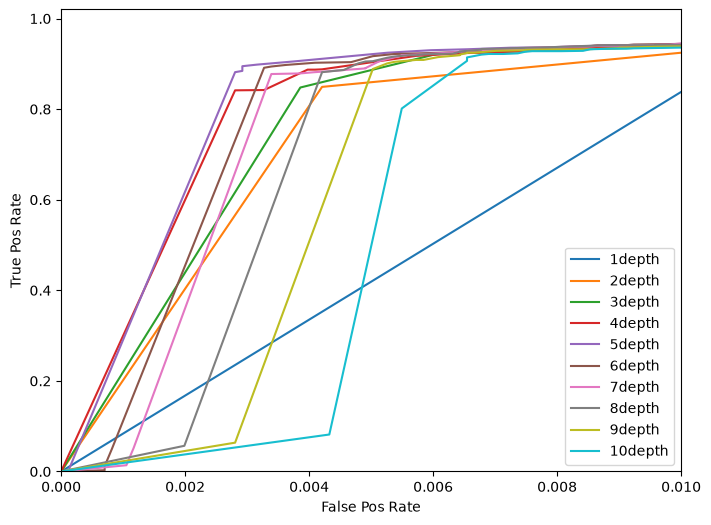

In [29]:
#Part8
#Reused code from 4
from sklearn.tree import DecisionTreeClassifier

plt.figure(figsize=(8, 6))

for i in range(1, 11):
    dt = DecisionTreeClassifier(max_depth=i, random_state=0)
    dt.fit(X_train[:, :4], y_train)

    qso_index = np.where(gmmb.classes_ == 1)[0][0]
    y_prob = dt.predict_proba(X_test[:, :4])[:, qso_index]

    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=str(i) + 'depth')

plt.xlim(0, 0.01)
plt.ylim(0, 1.02)
plt.xlabel('False Pos Rate')
plt.ylabel('True Pos Rate')
plt.legend()
plt.show()

A tree depth of 5 has the best performance which can be seen pretty clearly compared to the rest, beyond that doesn't seem to be beneficial though increasing from 1 to 5 is beneficial.

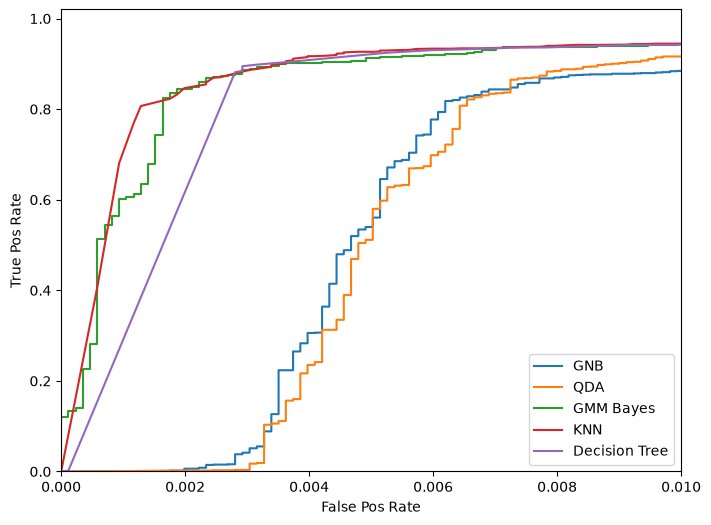

In [31]:
#part9
#combine parts 4-8
plt.figure(figsize=(8, 6))

models = [GaussianNB(), QuadraticDiscriminantAnalysis(),
          GMMBayes(n_components=10, covariance_type='full'),
          KNeighborsClassifier(n_neighbors=95),
          DecisionTreeClassifier(max_depth=5, random_state=0)]
names = ['GNB', 'QDA', 'GMM Bayes', 'KNN', 'Decision Tree']

for model, name in zip(models, names):
    model.fit(X_train[:, :4], y_train)

    qso_index = np.where(model.classes_ == 1)[0][0]
    y_prob = model.predict_proba(X_test[:, :4])[:, qso_index]

    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.xlim(0, 0.01)
plt.ylim(0, 1.02)
plt.xlabel('False Pos Rate')
plt.ylabel('True Pos Rate')
plt.legend()
plt.show()

the KNN classifier has the best overall performance in the low false positive rate area and comparable performance with Decision Tree and GMM Bayes later on and well out performs GNB and QDA

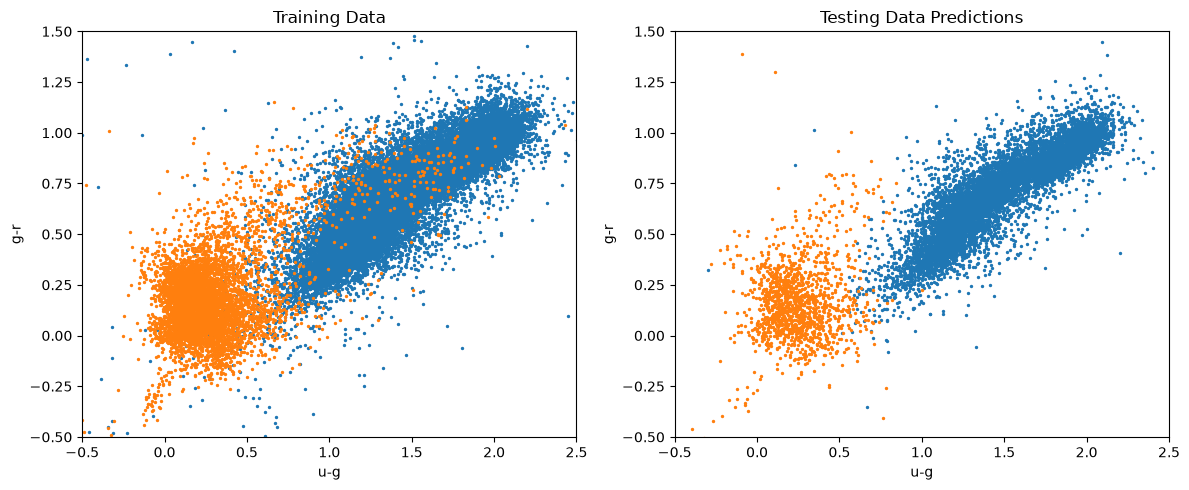

In [36]:
#part 10
knn = KNeighborsClassifier(n_neighbors=95)
knn.fit(X_train[:, :4], y_train)

y_pred = knn.predict(X_test[:, :4])

plt.figure(figsize=(12, 5))

#create training data
plt.subplot(121)
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], s=2, label='Galaxy')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], s=2, label='Quasar')
plt.title('Training Data')
plt.xlabel('u-g')
plt.ylabel('g-r')
plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 1.5)
plt.legend

#predictins
plt.subplot(122)
plt.scatter(X_test[y_pred == 0, 0], X_test[y_pred == 0, 1], s=2, label='Galaxy')
plt.scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1], s=2, label='Quasar')
plt.title('Testing Data Predictions')
plt.xlabel('u-g')
plt.ylabel('g-r')
plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 1.5)
plt.legend

plt.tight_layout()
plt.show()